# External validation on GSE129785 (Satpathy 2019)

Reads tables from `../data/` and writes figures to `../output/`.
Source analysis: `../../NOTEBOOK_PROVENANCE.tsv`.

The same controlled comparison as the atlas notebook, repeated on an
independent cohort: FACS-sorted blood from Satpathy et al. 2019. Because the
populations are sorted rather than clustered, the label set here is the sorted
population (`group`) mapped onto an atlas label, and the donor is the
individual -- so `celltype` is the colouring that carries the biology.

All seven representations were built from the same cells and the same
fragments per cell, as on the atlas.

Panels, drawn at main-figure size (180 mm / 7.08 in double-column width, 5-6 pt
text) so they go into the figure at 100%:
- `scatac_gse129785_umap_panel_by_celltype_main`: one UMAP per representation,
  coloured by sorted population, annotated with that representation's ARI.
- `scatac_gse129785_scib_summary_main`: the scIB panel across the same seven
  representations. Cross-donor kNN purity is dropped: every sorted population
  spans every donor here, which is a property of the design rather than a
  result, so the metric carries no information in this cohort.

The reviewer-response versions of these two panels
(`output/scatac/ext_gse129785/panel_matched_classifier_probabilities_by_celltype.png`,
`scib_matched_classifier_probabilities.png`) were drawn about 16 and 9 inches
wide and are not reproduced here. Against them, only the layout changes: the
UMAP row becomes two rows of four with the legend in the eighth slot, the scIB
legend moves above the chart, long titles are wrapped, the two `CONTROL:`
population labels are written as plain names, and the scIB chart names and colours
both LEAF-1 rows as LEAF-1 (blue; the coordinate bins move to grey). Point data, metric
values and row order are unchanged.

In [1]:
from pathlib import Path
import sys

# Self-contained: works when run from notebook/, from the modality folder, or from the repo root.
nb_dir = Path.cwd()
if (nb_dir / "data").exists() and (nb_dir / "output").exists():
    MOD_DIR = nb_dir
elif (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

# Locate the shared style helper (src/leaf1figures) by walking up.
_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))

from leaf1figures.style import OKABE_ITO, savefig, set_paper_style
set_paper_style()
print("DATA:", DATA.relative_to(_p))
print("OUT :", OUT.relative_to(_p))

DATA: scatac/data
OUT : scatac/output


In [2]:
# ── Constants ─────────────────────────────────────────────────────────────────
import pandas as pd
import matplotlib.pyplot as plt

FAMILY_COLOR = {"SnapATAC": OKABE_ITO["green"], "binning (norm)": OKABE_ITO["blue"],
                "binning (raw)": OKABE_ITO["sky"], "LEAF-1": OKABE_ITO["orange"],
                "classifier probs": OKABE_ITO["purple"]}
METRICS = [("ari", "ARI"), ("nmi", "NMI"), ("asw_celltype", "cell-type ASW"),
           ("clisi", "cLISI"), ("isolated_label_asw", "isolated-label ASW"),
           ("cross_donor_knn_purity", "cross-donor kNN purity")]
DROP_METRICS = ["cross_donor_knn_purity"]
PANEL_RC = {
    "font.sans-serif": ["Arial", "DejaVu Sans", "Helvetica", "Liberation Sans"],
    "font.size": 6, "axes.titlesize": 7, "axes.labelsize": 6,
    "xtick.labelsize": 5, "ytick.labelsize": 5, "legend.fontsize": 5,
    # Matplotlib's default tick width, not the shared style's 0.5: the scIB
    # chart inherits the analysis script's rcParams, which never narrowed them.
    "xtick.major.width": 0.8, "ytick.major.width": 0.8,
}
# The dot chart's row labels are half a point larger than the UMAP row's, which
# is what sets the width of the label column and so the width of the whole chart.
SCIB_RC = {**PANEL_RC, "ytick.labelsize": 5.5}

coords = pd.read_csv(DATA / "scatac_gse129785_umap_coords.csv.gz")
# round_trip: pandas' default float parser is not correctly rounded, and the
# last bit of a metric is enough to move an autoscaled axis limit onto a
# different tick and shift the whole chart by a pixel.
scib = pd.read_csv(DATA / "scatac_gse129785_scib_metrics.csv", float_precision="round_trip")
TAGS = scib.tag.tolist()
TITLES = dict(zip(scib.tag, scib.title))
ARI = dict(zip(scib.tag, scib.ari))
print(coords.groupby("tag").size().to_string())
print()
print(scib[["tag", "title", "ari", "nmi"]].to_string(index=False))


def arrow_axes(ax):
    """Replace the frame with a small UMAP1/UMAP2 axis corner."""
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_visible(False)
    (x0, x1), (y0, y1) = ax.get_xlim(), ax.get_ylim()
    dx, dy = (x1 - x0) * 0.12, (y1 - y0) * 0.12
    bx, by = x0 + (x1 - x0) * 0.04, y0 + (y1 - y0) * 0.04
    ax.annotate("", xy=(bx + dx, by), xytext=(bx, by),
                arrowprops=dict(arrowstyle="->", color="black", lw=0.5))
    ax.annotate("", xy=(bx, by + dy), xytext=(bx, by),
                arrowprops=dict(arrowstyle="->", color="black", lw=0.5))
    ax.text(bx + dx / 2, by - (y1 - y0) * 0.04, "UMAP1", ha="center",
            va="top", fontsize=4.5)
    ax.text(bx - (x1 - x0) * 0.04, by + dy / 2, "UMAP2", ha="right",
            va="center", rotation=90, fontsize=4.5)

tag
ext_prob_retrained_cell      1400
gse_bin100kb_norm            1400
gse_bin10kb_norm             1400
gse_bin300kb_norm            1400
gse_bin30kb_norm             1400
gse_prob_snapregions_cell    1400
gse_snapdonor-mnc            1400

                      tag                                  title      ari      nmi
  ext_prob_retrained_cell                                 LEAF-1 0.397989 0.584302
gse_prob_snapregions_cell               LEAF-1, SnapATAC regions 0.467798 0.603521
        gse_bin300kb_norm Coordinate bins 300kb, log1p + z-score 0.424865 0.653871
        gse_bin100kb_norm Coordinate bins 100kb, log1p + z-score 0.446770 0.681983
         gse_bin30kb_norm  Coordinate bins 30kb, log1p + z-score 0.394366 0.593818
         gse_bin10kb_norm  Coordinate bins 10kb, log1p + z-score 0.310823 0.509903
        gse_snapdonor-mnc     SnapATAC 5 kb + MNC (Zhang et al.) 0.099203 0.248510


In [3]:
# ── Colours for the sorted populations ────────────────────────────────────────
# These are not the atlas's tissue categories, so they take the generic
# qualitative palette rather than the Figure 2d hues.
LABEL_COL = "group"
levels = sorted(coords[LABEL_COL].astype(str).unique())
palette = list(plt.get_cmap("tab20").colors) + list(plt.get_cmap("tab20b").colors)
colors = {lv: palette[i % len(palette)] for i, lv in enumerate(levels)}
print(dict(zip(levels, colors.values())))

{'CONTROL:CD34_Progenitors': (0.12156862745098039, 0.4666666666666667, 0.7058823529411765), 'CONTROL:Dendritic_Cells': (0.6823529411764706, 0.7803921568627451, 0.9098039215686274), 'Macrophage (General)': (1.0, 0.4980392156862745, 0.054901960784313725), 'Memory B Cell': (1.0, 0.7333333333333333, 0.47058823529411764), 'Naive T cell': (0.17254901960784313, 0.6274509803921569, 0.17254901960784313), 'Natural Killer T Cell': (0.596078431372549, 0.8745098039215686, 0.5411764705882353), 'T Lymphocyte 1 (CD8+)': (0.8392156862745098, 0.15294117647058825, 0.1568627450980392), 'T lymphocyte 2 (CD4+)': (1.0, 0.596078431372549, 0.5882352941176471)}


In [4]:
# ── scIB table: representation family, row order, metrics ────────────────────
def family(tag: str) -> str:
    for pre in ("dryad_", "gse_"):
        if tag.startswith(pre):
            tag = tag[len(pre):]
            break
    if tag.startswith("pool-mean") or tag.startswith("meanpool"):
        return "LEAF-1"
    if tag.startswith("ext_"):
        return "LEAF-1" if tag == "ext_meanpool" else "classifier probs"
    if tag.startswith("snap"):
        return "SnapATAC"
    if tag.startswith("prob"):
        return "classifier probs"
    if tag.startswith("leaf1"):
        return "LEAF-1"
    return "binning (raw)" if tag.endswith("_raw") else "binning (norm)"


df = scib.sort_values("ari").reset_index(drop=True)
df["family"] = df["tag"].map(family)
metrics = [(k, c) for k, c in METRICS
           if k not in DROP_METRICS and df[k].notna().any()]
ypos = range(len(df))
print(df[["title", "family"] + [k for k, _ in metrics]].to_string(index=False))

                                 title           family      ari      nmi  asw_celltype    clisi  isolated_label_asw
    SnapATAC 5 kb + MNC (Zhang et al.)         SnapATAC 0.099203 0.248510      0.484715 0.644943            0.480225
 Coordinate bins 10kb, log1p + z-score   binning (norm) 0.310823 0.509903      0.341667 0.772620            0.367956
 Coordinate bins 30kb, log1p + z-score   binning (norm) 0.394366 0.593818      0.384276 0.772968            0.397816
                                LEAF-1 classifier probs 0.397989 0.584302      0.564006 0.861108            0.647047
Coordinate bins 300kb, log1p + z-score   binning (norm) 0.424865 0.653871      0.486187 0.838861            0.514809
Coordinate bins 100kb, log1p + z-score   binning (norm) 0.446770 0.681983      0.430329 0.822564            0.443070
              LEAF-1, SnapATAC regions classifier probs 0.467798 0.603521      0.564225 0.856098            0.650322


## Main-figure panels

In [5]:
# ── Main-figure settings ──────────────────────────────────────────────────────
import textwrap
from matplotlib.ticker import MaxNLocator

MAIN_WIDTH = 7.08   # in; 180 mm double column
MAIN_RC = {
    "font.sans-serif": ["Arial", "DejaVu Sans", "Helvetica", "Liberation Sans"],
    "font.size": 6, "axes.titlesize": 6, "axes.labelsize": 6,
    "xtick.labelsize": 5, "ytick.labelsize": 6, "legend.fontsize": 6,
}
# Display names for the sorted populations; every other label is shown as is.
POP_DISPLAY = {"CONTROL:CD34_Progenitors": "CD34+ progenitors",
               "CONTROL:Dendritic_Cells": "Dendritic cells"}


def wrap_title(s, width=24):
    return "\n".join(textwrap.wrap(s, width))

saved: scatac/output/scatac_gse129785_umap_panel_by_celltype_main.pdf
saved: scatac/output/scatac_gse129785_umap_panel_by_celltype_main.png
saved: scatac/output/scatac_gse129785_umap_panel_by_celltype_main.svg
saved: scatac/output/scatac_gse129785_umap_panel_by_celltype_main.tsv


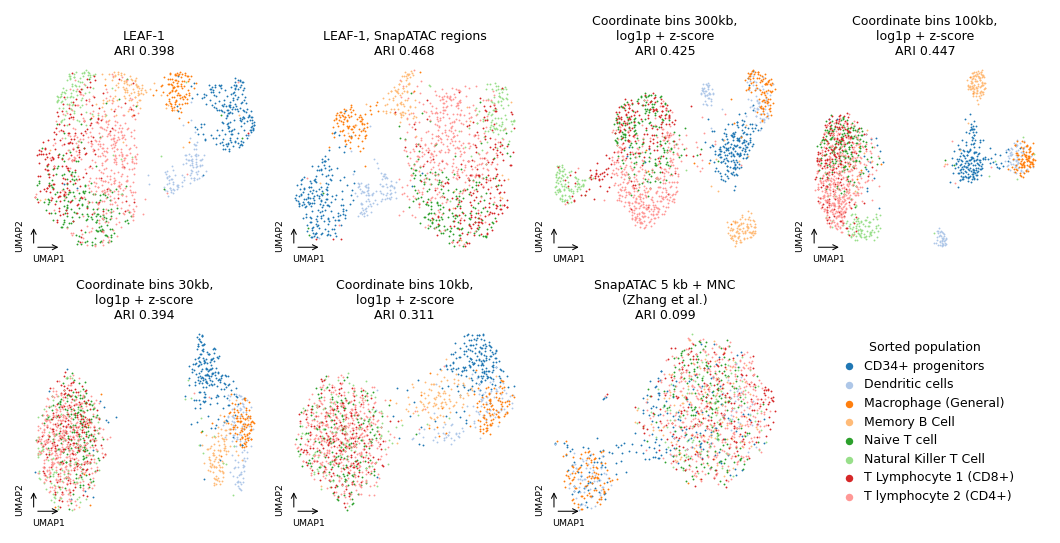

In [6]:
# ── Main figure: UMAP grid, coloured by sorted population ─────────────────────
# Same colour per population as the response version (`colors` from above).
with plt.rc_context(MAIN_RC):
    fig, axes = plt.subplots(2, 4, figsize=(MAIN_WIDTH, 3.6))
    axes = axes.ravel()
    for ax, tag in zip(axes, TAGS):
        pts = coords[coords.tag == tag]
        for lv, color in colors.items():
            m = pts[LABEL_COL].astype(str) == str(lv)
            if m.any():
                ax.scatter(pts.loc[m, "umap1"], pts.loc[m, "umap2"], s=0.8,
                           c=[color], label=POP_DISPLAY.get(lv, lv),
                           linewidth=0, rasterized=True)
        arrow_axes(ax)
        ax.set_title(f"{wrap_title(TITLES[tag])}\nARI {ARI[tag]:.3f}", loc="center", pad=3)

    leg_ax = axes[len(TAGS)]
    leg_ax.axis("off")
    handles, labels = axes[0].get_legend_handles_labels()
    leg_ax.legend(handles, labels, loc="center", frameon=False, markerscale=4,
                  handletextpad=0.2, labelspacing=0.45, borderaxespad=0,
                  title="Sorted population", title_fontsize=6)
    for ax in axes[len(TAGS) + 1:]:
        ax.axis("off")
    fig.tight_layout(h_pad=1.2, w_pad=0.8)
    savefig(fig, OUT, "scatac_gse129785_umap_panel_by_celltype_main",
            data=scib[["tag", "title", "ari"]])
    plt.show()

saved: scatac/output/scatac_gse129785_scib_summary_main.pdf
saved: scatac/output/scatac_gse129785_scib_summary_main.png
saved: scatac/output/scatac_gse129785_scib_summary_main.svg
saved: scatac/output/scatac_gse129785_scib_summary_main.tsv


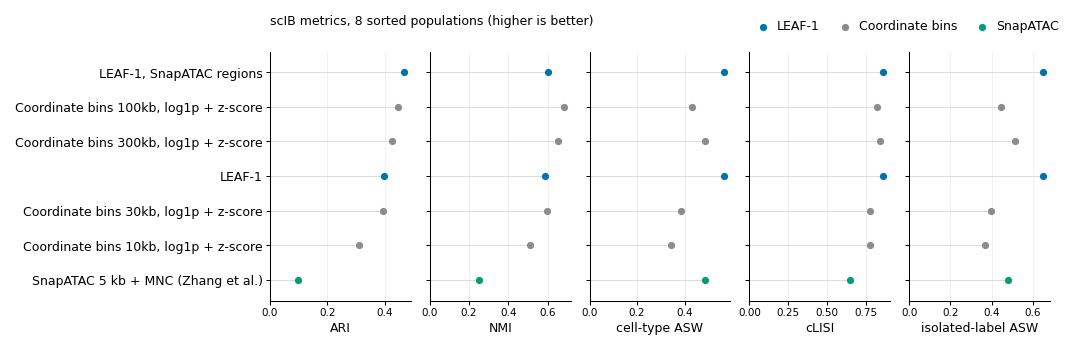

In [7]:
# ── Main figure: scIB metrics ─────────────────────────────────────────────────
# Same rows (sorted by ARI) and metrics as the response version. Both LEAF-1
# rows are named and coloured as LEAF-1 -- the blue it has in every other
# figure -- so the coordinate bins move from blue to grey, the comparator grey
# of Fig. 4.
MAIN_FAMILY = {"classifier probs": ("LEAF-1", OKABE_ITO["blue"]),
               "binning (norm)": ("Coordinate bins", "#8C8C8C"),
               "SnapATAC": ("SnapATAC", OKABE_ITO["green"])}
df_main = df.assign(family=df["family"].map(lambda f: MAIN_FAMILY[f][0]))
main_color = {name: col for name, col in MAIN_FAMILY.values()}
with plt.rc_context(MAIN_RC):
    fig, axes = plt.subplots(1, len(metrics), figsize=(MAIN_WIDTH, 2.3), sharey=True)
    for ax, (key, cap) in zip(axes, metrics):
        ax.hlines(list(ypos), 0, df_main[key], color="#DDDDDD", lw=0.5, zorder=1)
        for fam, sub in df_main.groupby("family"):
            ax.scatter(sub[key], sub.index, s=12, color=main_color[fam],
                       label=fam, zorder=3, linewidth=0)
        ax.set_xlabel(cap, labelpad=2)
        ax.set_xlim(left=0)
        ax.xaxis.set_major_locator(MaxNLocator(nbins=4, steps=[1, 2, 2.5, 5, 10]))
        ax.grid(axis="x", color="#EEEEEE", lw=0.4, zorder=0)
        ax.set_axisbelow(True)
        ax.tick_params(axis="both", length=2, pad=1.5)
    axes[0].set_yticks(list(ypos))
    axes[0].set_yticklabels(df_main["title"])
    axes[0].set_ylim(-0.6, len(df) - 0.4)
    by_label = dict(zip(*reversed(axes[0].get_legend_handles_labels())))
    l2 = [name for name, _ in MAIN_FAMILY.values() if name in by_label]
    h2 = [by_label[name] for name in l2]
    fig.tight_layout(w_pad=0.6, rect=(0, 0, 1, 0.9))
    fig.legend(h2, l2, loc="lower right", bbox_to_anchor=(1.0, 0.9), ncol=len(l2),
               frameon=False, handletextpad=0.1, columnspacing=1.0, borderaxespad=0)
    fig.text(axes[0].get_position().x0, 0.93,
             f"scIB metrics, {df.iloc[0]['n_levels_label']} sorted populations "
             f"(higher is better)", ha="left", va="bottom", fontsize=6)
    savefig(fig, OUT, "scatac_gse129785_scib_summary_main",
            data=df_main[["tag", "title", "family"] + [k for k, _ in metrics]])
    plt.show()